# 02 — DiD: koreksi bias tren

Notebook ini menjalankan **satu spesifikasi yang sama persis** pada tiga frost Juli
(2016, 2019, 2021), lalu melaporkan **dua versi kontrol tren** berdampingan.

Spesifikasi mengikuti CLAUDE.md §4 (versi terkoreksi 2026-09-20):

```
gap_t = log(arabica_t) − log(robusta_t)
gap ~ bin_0_5 + bin_6_11 + bin_12_18 + tren + log(brl_usd)
HAC standard errors, maxlags = 12
```

Jendela: 12 bulan pra-event, 18 bulan pasca-event. Panjang bin, panjang jendela, dan
daftar event **tidak diubah** dalam notebook ini.

In [1]:
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from src.ingestion.events import load_events
from src.processing.build_panel import build_panel
from src.processing.event_study import (
    HAC_LAGS,
    POST_BINS,
    PRE_MONTHS,
    POST_MONTHS,
    _gap,
    compare_trend_specs,
    event_window,
)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)

panel = build_panel(weather_end="20260831")
events = load_events("../data/events.csv")
used = events[events.use.isin(["treatment", "placebo"])].sort_values("event_date")

print(f"jendela: −{PRE_MONTHS} s/d +{POST_MONTHS} bulan | HAC maxlags = {HAC_LAGS}")
used[["event_date", "event_type", "severity", "use"]]

jendela: −12 s/d +18 bulan | HAC maxlags = 12


,event_date,event_type,severity,use
0,2016-07-01,frost_scare,none,placebo
1,2019-07-01,frost_scare,none,placebo
2,2021-07-20,frost,severe,treatment


## Kenapa dua versi tren dilaporkan, bukan satu

**Ini bagian metodologi — masuk ke README.**

Selisih harga Arabika–Robusta sudah menanjak **sebelum** frost Juli 2021 (kekeringan
2020–21 dan tahun *off-season* biennial, keduanya khusus Arabika). Tren waktu karena
itu wajib dikontrol; tanpa itu, kenaikan yang sudah berjalan akan dihitung sebagai
efek frost.

Masalahnya, **cara mengontrol tren menentukan hasilnya**, dan dua cara yang sama-sama
lazim memberi jawaban berbeda:

**(a) Tren full-window** — satu garis lurus dicocokkan ke seluruh 31 bulan (pra + pasca).
Kelemahannya serius di sini: efek yang diperkirakan **menanjak bertahap sampai puncak
di bulan ~11** bentuknya nyaris sama dengan garis lurus menanjak. Tren dan efek jadi
hampir kolinear, sehingga tren **menyerap sebagian efek yang seharusnya ia ukur**.

**(b) Tren pre-only (praktik baku ITS)** — garis tren diestimasi **hanya dari 12 bulan
pra-event**, lalu diproyeksikan ke depan sebagai *counterfactual*: "seandainya tidak ada
frost, gap akan berada di sini". Efek diukur sebagai simpangan dari proyeksi itu. Tren
tidak bisa menyerap efek, karena tren tidak pernah melihat data pasca-event.

Versi (b) punya harga yang harus dibayar: proyeksinya diperlakukan sebagai **diketahui
pasti**, padahal ia sendiri hasil estimasi dari 12 titik. Standard error tahap kedua
karena itu **terlalu kecil** — p-value versi (b) tidak boleh dibaca seketat versi (a).

**Keduanya dilaporkan justru karena hasilnya berbeda.** Memilih salah satu setelah
melihat mana yang lebih mendukung hipotesis adalah seleksi berbasis hasil — kesalahan
yang sama dengan menyetel ambang frost, dan sudah ditolak di CLAUDE.md §3. Kalau sebuah
temuan hanya muncul di satu dari dua spesifikasi yang sama-sama masuk akal, maka
temuan itu memang rapuh, dan pembaca berhak tahu.

## Hipotesis yang diuji

Jika efek yang terukur di 2021 benar-benar berasal dari kerusakan pasokan akibat frost:

1. Koefisien 2021 pada bin **6–11 bulan** positif dan bertahan di kedua versi (mekanisme
   ICO: dampak produksi masuk di tahun panen 2022/23).
2. Placebo 2016 dan 2019 — frost yang **tidak** merusak — mestinya kecil, transien, atau nol.
3. Koreksi tren pre-only mestinya **memperbesar** estimasi 2021, karena versi full-window
   diduga menyerap sebagian efek.

In [2]:
comparison = pd.concat([compare_trend_specs(panel, r.event_date) for _, r in used.iterrows()])

wide = comparison.unstack("bin")
order = [(stat, b) for b in ["post_0_5", "post_6_11", "post_12_18"] for stat in ["coef", "se", "p", "pct"]]
wide = wide[order]
wide.columns = pd.MultiIndex.from_tuples(
    [(b.replace("post_", "").replace("_", "–") + " bln", s) for s, b in wide.columns]
)
print("Efek pada gap log(Arabika) − log(Robusta), dua versi kontrol tren")
print("(coef = log poin, pct = persen, p dari HAC maxlags=12)\n")
print(wide.round(4).to_string())

Efek pada gap log(Arabika) − log(Robusta), dua versi kontrol tren
(coef = log poin, pct = persen, p dari HAC maxlags=12)

                             0–5 bln                          6–11 bln                          12–18 bln                         
                                coef      se       p      pct     coef      se       p      pct      coef      se       p      pct
event   versi                                                                                                                     
2016-07 (a) tren full-window -0.0882  0.0274  0.0013  -8.4377  -0.2684  0.0547  0.0000 -23.5432   -0.3072  0.0705  0.0000 -26.4480
        (b) tren pre-only    -0.1155  0.0204  0.0000 -10.9121  -0.3183  0.0138  0.0000 -27.2604   -0.3848  0.0063  0.0000 -31.9437
2019-07 (a) tren full-window  0.0529  0.0181  0.0035   5.4274   0.0716  0.0266  0.0071   7.4191   -0.0118  0.0387  0.7595  -1.1778
        (b) tren pre-only     0.0744  0.0124  0.0000   7.7217   0.1776  0.0151  0.0000  19.4

**Interpretasi tabel:**

Hipotesis 3 **ditolak**. Koreksi pre-only justru **mengecilkan** estimasi 2021 pada bin
6–11 bulan, dari +11,4% menjadi +7,2%. Penyebabnya bisa dilacak: slope pra-event 2021
positif (+0,0039/bulan), sehingga *counterfactual*-nya ikut menanjak — dan simpangan
harga aktual terhadap garis yang menanjak jadi lebih kecil, bukan lebih besar. Dugaan
bahwa tren full-window "memakan" efek ternyata tidak terbukti di data ini.

Hipotesis 2 juga **tidak terpenuhi**. Placebo 2019 (frost tanpa kerusakan) malah menguat
di versi pre-only: +19,4% pada 6–11 bulan dan +14,9% pada 12–18 bulan — lebih besar
daripada treatment 2021 di kedua bin. Placebo 2016 bergerak kuat ke arah negatif (−27%
sampai −32%), yang hampir pasti mengukur kemerosotan Arabika 2017–18, bukan efek frost.

Hipotesis 1 bertahan **hanya secara tanda**: 2021 pada bin 6–11 positif di kedua versi
(+11,4% dan +7,2%), di jendela yang persis diramalkan mekanisme ICO. Tapi besarannya
berubah 60% tergantung spesifikasi, dan placebo-nya lebih besar.

Sesuai CLAUDE.md §4, uji placebo pada frekuensi bulanan memang **tidak bisa
diinterpretasikan** — jendela 2019 dan 2021 tumpang tindih 7 bulan. Jadi ini bukan bukti
bahwa frost tidak berdampak; ini bukti bahwa **desain bulanan tidak mampu menjawabnya**.

## Diagnostik: standard error versi (b) tidak bisa dipercaya

HAC `maxlags=12` diwajibkan CLAUDE.md §4. Pada tahap kedua versi (b), sampelnya hanya
**19 observasi** pasca-event, sehingga jumlah lag hampir sepanjang sampel itu sendiri.
Tanda bahaya: SE **mengecil** ketika lag ditambah, padahal koreksi HAC untuk deret
berautokorelasi positif semestinya **membesarkan** SE.

In [3]:
window = event_window(panel, pd.Timestamp("2021-07-20"))
gap = _gap(window)
X = sm.add_constant(pd.DataFrame(
    {"trend": window.k.values, "log_brl": np.log(window.brl_usd).values}, index=window.index
))
pre = window[window.k < 0]
baseline = sm.OLS(gap.loc[pre.index], X.loc[pre.index]).fit()
deviation = gap - baseline.predict(X)
post = window[window.k >= 0]
bins = pd.DataFrame(
    {n: ((post.k >= lo) & (post.k <= hi)).astype(float).values for n, (lo, hi) in POST_BINS.items()},
    index=post.index,
)

rows = []
for lags in [None, 0, 3, 6, 12]:
    if lags is None:
        fit = sm.OLS(deviation.loc[post.index], bins).fit()
        label = "OLS biasa (tanpa HAC)"
    else:
        fit = sm.OLS(deviation.loc[post.index], bins).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
        label = f"HAC maxlags={lags}"
    rows.append({"spesifikasi": label, "se_6_11": fit.bse["post_6_11"], "p_6_11": fit.pvalues["post_6_11"]})

print(f"n pasca-event = {len(post)} observasi\n")
print(pd.DataFrame(rows).round(4).to_string(index=False))
print(f"\nSE naif (sd/akar n) pada bin 6–11: "
      f"{deviation[(window.k >= 6) & (window.k <= 11)].std() / np.sqrt(6):.4f}")

n pasca-event = 19 observasi

          spesifikasi  se_6_11  p_6_11
OLS biasa (tanpa HAC)   0.0185  0.0018
        HAC maxlags=0   0.0074  0.0000
        HAC maxlags=3   0.0052  0.0000
        HAC maxlags=6   0.0046  0.0000
       HAC maxlags=12   0.0034  0.0000

SE naif (sd/akar n) pada bin 6–11: 0.0081


**Interpretasi:**

SE turun dari 0,0185 (OLS biasa) ke 0,0034 (HAC-12) — mengecil **5 kali lipat**. Bahkan
SE naif `sd/√n` (0,0081) lebih besar daripada HAC-12. Ini bukan koreksi, ini kegagalan
estimator pada sampel kecil.

Konsekuensinya: **p-value pada versi (b) tidak boleh dikutip sebagai bukti.** Yang layak
dibaca dari versi (b) hanya besaran koefisiennya. Rekomendasi untuk CLAUDE.md §4: wajibkan
`maxlags=12` hanya untuk regresi yang memakai seluruh 31 bulan, dan turunkan lag (atau
pakai SE biasa) untuk tahap kedua ITS yang cuma 19 observasi.

## Visual: harga aktual vs counterfactual

**Hipotesis:** jika frost menyebabkan lonjakan, garis aktual akan memisahkan diri ke atas
dari garis proyeksi tepat setelah k = 0 — dan hanya pada event yang benar-benar merusak.

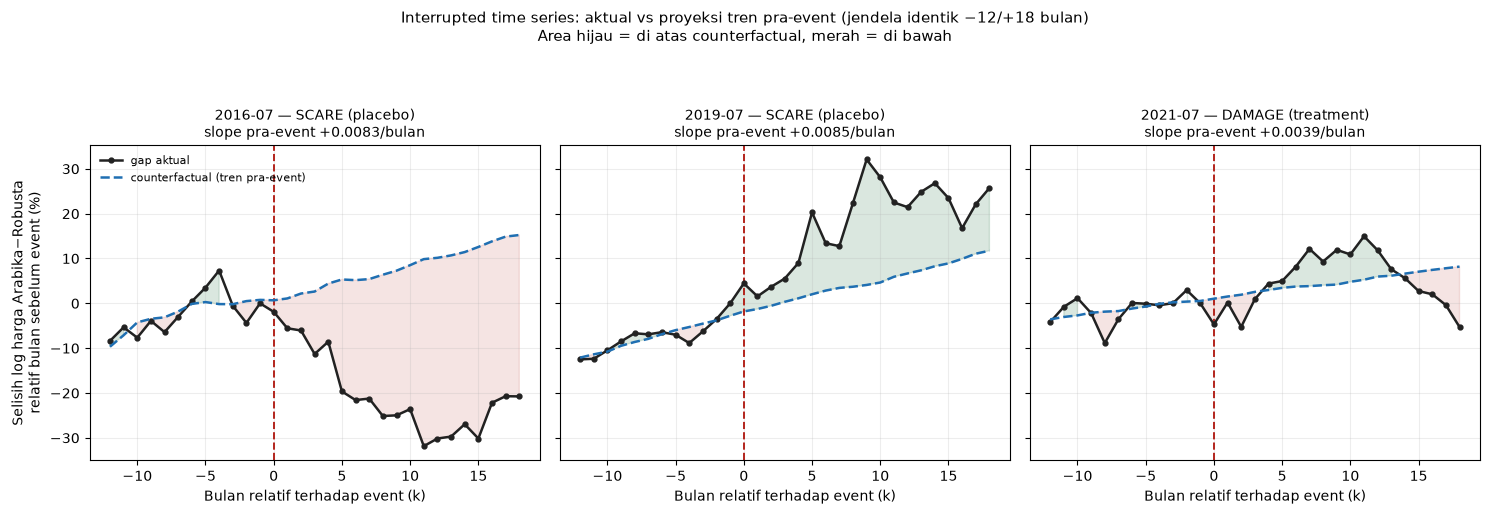

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
titles = {
    "2016-07": "2016-07 — SCARE (placebo)",
    "2019-07": "2019-07 — SCARE (placebo)",
    "2021-07": "2021-07 — DAMAGE (treatment)",
}

for ax, (_, r) in zip(axes, used.iterrows()):
    w = event_window(panel, r.event_date)
    g = _gap(w)
    Xw = sm.add_constant(pd.DataFrame(
        {"trend": w.k.values, "log_brl": np.log(w.brl_usd).values}, index=w.index
    ))
    pre_w = w[w.k < 0]
    fit_pre = sm.OLS(g.loc[pre_w.index], Xw.loc[pre_w.index]).fit()
    cf = fit_pre.predict(Xw)
    base = g.loc[w.index[w.k == -1]].iloc[0]

    ax.axvline(0, color="#B3241C", ls="--", lw=1.4)
    ax.plot(w.k, (g - base) * 100, color="#222", lw=1.8, marker="o", ms=3.5, label="gap aktual")
    ax.plot(w.k, (cf - base) * 100, color="#1F6FB2", lw=1.8, ls="--",
            label="counterfactual (tren pra-event)")
    ax.fill_between(w.k, (cf - base) * 100, (g - base) * 100,
                    where=(g >= cf), color="#1B6B3A", alpha=0.16)
    ax.fill_between(w.k, (cf - base) * 100, (g - base) * 100,
                    where=(g < cf), color="#B3241C", alpha=0.12)

    ax.set_title(f"{titles[f'{r.event_date:%Y-%m}']}\nslope pra-event {fit_pre.params['trend']:+.4f}/bulan",
                 fontsize=10)
    ax.set_xlabel("Bulan relatif terhadap event (k)")
    ax.grid(alpha=0.22)

axes[0].set_ylabel("Selisih log harga Arabika−Robusta\nrelatif bulan sebelum event (%)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle(
    "Interrupted time series: aktual vs proyeksi tren pra-event (jendela identik −12/+18 bulan)\n"
    "Area hijau = di atas counterfactual, merah = di bawah",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIG_DIR / "06_its_counterfactual.png", dpi=150)
plt.show()

**Interpretasi:**

Panel 2021 memperlihatkan pola yang paling sesuai teori: aktual menempel pada
counterfactual selama ~5 bulan, lalu naik di atasnya sekitar bulan 6–11, lalu jatuh
kembali ke bawah setelah bulan 12. Bentuk itu cocok dengan mekanisme panen tertunda.

Tapi panel 2019 memperlihatkan **pemisahan ke atas yang lebih besar dan lebih lama**,
padahal ICO mencatat kekhawatiran frost saat itu justru mereda tanpa kerusakan. Selama
dua panel itu tidak bisa dibedakan, klaim kausal untuk 2021 belum berdiri.

Panel 2016 memperlihatkan hal ketiga lagi: aktual jatuh jauh di bawah counterfactual —
konsisten dengan kemerosotan Arabika 2017–18 yang tidak ada hubungannya dengan frost.

## Ringkasan

| Hipotesis | Hasil |
|---|---|
| Koreksi pre-only memperbesar estimasi 2021 | ❌ justru mengecil (+11,4% → +7,2%) |
| Placebo kecil/nol, treatment besar | ❌ placebo 2019 lebih besar di kedua versi |
| 2021 positif pada bin 6–11 di kedua versi | ✅ bertahan secara tanda (+11,4% / +7,2%) |
| SE versi (b) layak dikutip | ❌ HAC degenerate pada n=19 |

**Kesimpulan metodologis:** satu-satunya hasil yang bertahan lintas spesifikasi adalah
**tanda** efek 2021 pada bin 6–11 bulan, di jendela yang diramalkan mekanisme ICO.
Besarannya tidak stabil, dan uji placebo bulanan tidak bisa diinterpretasikan karena
jendelanya tumpang tindih.

**Langkah berikutnya (sesuai CLAUDE.md §4):** event study harian dengan jendela
±10 hari perdagangan, di mana confounder lambat (kekeringan, siklus biennial) praktis
konstan dan jendela ketiga event tidak lagi bertumpuk.